# Mineração de Processos Aplicada ao Transporte Público: Tratamento de Dados de GPS e Descoberta de Fluxos na URBS

**Autor:** Arthur de Barros Marcondes Machado Rosisca  
**Universidade:** UTFPR - Campus Ponta Grossa  
**Data:** 2026  

Este notebook implementa a metodologia completa para análise de dados de transporte público da URBS utilizando Process Mining.

## Seção 1: Carregamento e Filtragem de Dados Brutos de GPS

**Objetivo:** Carregar todos os arquivos CSV de um dia específico, concatenar dados, remover registros inválidos, filtrar para um ônibus alvo e selecionar colunas essenciais.

**Colunas mantidas:**
- `request_timestamp`: Hora da transmissão GPS
- `COD`: Código único do ônibus
- `LAT`, `LON`: Coordenadas geográficas
- `CODIGOLINHA`: Código da linha de transporte
- `SITUACAO`, `SITUACAO2`: Status operacional
- `SENT`: Sentido da linha

In [6]:
import pandas as pd
import numpy as np
import glob
import os
from datetime import datetime, timedelta
import folium
import geopandas as gpd
from shapely.geometry import Point
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# PASSO 1: INGESTÃO DE DADOS COM ENRIQUECIMENTO
# ==========================================
def carregar_dados_enriquecidos(pasta_dia, onibus_alvo):
    """
    Lê todos os arquivos CSV de um dia específico, filtra um ônibus e preserva colunas de status.
    
    Args:
        pasta_dia (str): Caminho da pasta contendo CSVs do dia
        onibus_alvo (str): Código do ônibus a ser analisado
        
    Returns:
        pd.DataFrame: Dados filtrados e ordenados por timestamp
    """
    print(f"1. Carregando arquivos da pasta: {pasta_dia}...")
    caminho_arquivos = f"{pasta_dia}/*.csv"
    arquivos = glob.glob(caminho_arquivos)
    
    if not arquivos:
        print(f"   ⚠️  Nenhum arquivo CSV encontrado em {pasta_dia}")
        return pd.DataFrame()
    
    print(f"   ✓ {len(arquivos)} arquivos encontrados")
    
    # Lendo e juntando todos os CSVs
    df_lista = [pd.read_csv(arquivo) for arquivo in arquivos]
    df_bruto = pd.concat(df_lista, ignore_index=True)
    print(f"   ✓ Total de registros carregados: {len(df_bruto)}")
    
    print("\n2. Filtrando e preservando colunas vitais para o TCC...")
    
    # Remover linhas sem coordenadas válidas
    df_limpo = df_bruto.dropna(subset=['LAT', 'LON']).copy()
    print(f"   ✓ Registros com coordenadas válidas: {len(df_limpo)}")
    
    # Converter a coluna de tempo para datetime
    df_limpo['request_timestamp'] = pd.to_datetime(df_limpo['request_timestamp'])
    
    # Filtrar para o ônibus alvo
    df_filtrado = df_limpo[df_limpo['COD'] == onibus_alvo].copy()
    print(f"   ✓ Registros do ônibus {onibus_alvo}: {len(df_filtrado)}")
    
    # Ordenar cronologicamente
    df_filtrado = df_filtrado.sort_values(by='request_timestamp').reset_index(drop=True)
    
    # Selecionar colunas importantes
    colunas_importantes = ['request_timestamp', 'COD', 'LAT', 'LON', 'CODIGOLINHA', 'SITUACAO', 'SITUACAO2', 'SENT']
    
    # Verificar se todas as colunas existem
    colunas_existentes = [col for col in colunas_importantes if col in df_filtrado.columns]
    
    return df_filtrado[colunas_existentes]


# ==========================================
# EXECUÇÃO DA SEÇÃO 1
# ==========================================
print("=" * 60)
print("SEÇÃO 1: CARREGAMENTO DE DADOS")
print("=" * 60)

pasta_alvo = "dados_urbs/2025-12-31"
onibus_teste = "HI042"

df_bruto_enriquecido = carregar_dados_enriquecidos(pasta_alvo, onibus_teste)

if not df_bruto_enriquecido.empty:
    print(f"\n✓ Sucesso! Dados carregados com riqueza de informações:")
    print(f"  - Primeiros registros (head):")
    display(df_bruto_enriquecido.head(10))
    
    print(f"\n  - Informações gerais do DataFrame:")
    print(f"    Período: {df_bruto_enriquecido['request_timestamp'].min()} até {df_bruto_enriquecido['request_timestamp'].max()}")
    print(f"    Duração: {(df_bruto_enriquecido['request_timestamp'].max() - df_bruto_enriquecido['request_timestamp'].min()).total_seconds() / 3600:.2f} horas")
else:
    print(f"❌ Nenhum dado encontrado para o ônibus {onibus_teste} na pasta {pasta_alvo}.")

SEÇÃO 1: CARREGAMENTO DE DADOS
1. Carregando arquivos da pasta: dados_urbs/2025-12-31...
   ✓ 24 arquivos encontrados
   ✓ Total de registros carregados: 5782138

2. Filtrando e preservando colunas vitais para o TCC...
   ✓ Total de registros carregados: 5782138

2. Filtrando e preservando colunas vitais para o TCC...
   ✓ Registros com coordenadas válidas: 5782138
   ✓ Registros com coordenadas válidas: 5782138
   ✓ Registros do ônibus HI042: 4103

✓ Sucesso! Dados carregados com riqueza de informações:
  - Primeiros registros (head):
   ✓ Registros do ônibus HI042: 4103

✓ Sucesso! Dados carregados com riqueza de informações:
  - Primeiros registros (head):


,request_timestamp,COD,LAT,LON,CODIGOLINHA,SITUACAO,SITUACAO2,SENT
0,2025-12-31 00:00:11.374942,HI042,-25.496936,-49.342276,654,NO HORÁRIO,REALIZANDO ROTA,IDA
1,2025-12-31 00:00:32.301663,HI042,-25.496936,-49.342276,654,NO HORÁRIO,REALIZANDO ROTA,IDA
2,2025-12-31 00:00:54.206419,HI042,-25.496936,-49.342276,654,NO HORÁRIO,REALIZANDO ROTA,IDA
3,2025-12-31 00:01:15.881007,HI042,-25.496936,-49.342276,654,NO HORÁRIO,REALIZANDO ROTA,IDA
4,2025-12-31 00:01:37.032580,HI042,-25.483991,-49.347251,826,NO HORÁRIO,REALIZANDO ROTA,IDA
5,2025-12-31 00:01:57.627585,HI042,-25.483450,-49.348225,826,NO HORÁRIO,REALIZANDO ROTA,IDA
6,2025-12-31 00:02:18.012503,HI042,-25.483920,-49.349640,826,NO HORÁRIO,REALIZANDO ROTA,IDA
7,2025-12-31 00:02:38.575575,HI042,-25.483920,-49.349640,826,NO HORÁRIO,REALIZANDO ROTA,IDA
8,2025-12-31 00:02:59.219926,HI042,-25.483920,-49.349640,826,NO HORÁRIO,REALIZANDO ROTA,IDA
9,2025-12-31 00:03:19.759688,HI042,-25.483920,-49.349640,REC,NaN,NaN,NaN



  - Informações gerais do DataFrame:
    Período: 2025-12-31 00:00:11.374942 até 2025-12-31 23:59:59.275705
    Duração: 24.00 horas


## Seção 2: Limpeza de Dados e Validação

**Objetivo:** Validar dados, converter tipos, detectar e remover valores inválidos, e gerar estatísticas descritivas.

In [7]:
print("\n" + "=" * 60)
print("SEÇÃO 2: LIMPEZA E VALIDAÇÃO DE DADOS")
print("=" * 60)

# Função de validação de coordenadas
def validar_coordenadas(df):
    """Valida ranges de latitude e longitude"""
    valido = (
        (df['LAT'] >= -90) & (df['LAT'] <= 90) &
        (df['LON'] >= -180) & (df['LON'] <= 180)
    )
    return valido

if not df_bruto_enriquecido.empty:
    print(f"\n1. Validando coordenadas...")
    
    # Antes da validação
    registros_antes = len(df_bruto_enriquecido)
    
    # Aplicar validação
    mask_valido = validar_coordenadas(df_bruto_enriquecido)
    df_meu_onibus = df_bruto_enriquecido[mask_valido].copy()
    
    registros_depois = len(df_meu_onibus)
    removidos = registros_antes - registros_depois
    
    print(f"   ✓ Registros antes: {registros_antes}")
    print(f"   ✓ Registros depois: {registros_depois}")
    print(f"   ✓ Registros removidos (inválidos): {removidos}")
    
    # Remover duplicatas (mesma coordenada no mesmo segundo)
    print(f"\n2. Removendo duplicatas...")
    df_meu_onibus = df_meu_onibus.drop_duplicates(
        subset=['request_timestamp', 'LAT', 'LON'],
        keep='first'
    ).reset_index(drop=True)
    
    print(f"   ✓ Registros após remoção de duplicatas: {len(df_meu_onibus)}")
    
    # Estatísticas
    print(f"\n3. Estatísticas descritivas dos dados:")
    print(f"\n   Coordenadas geográficas:")
    print(f"      LAT: min={df_meu_onibus['LAT'].min():.6f}, max={df_meu_onibus['LAT'].max():.6f}")
    print(f"      LON: min={df_meu_onibus['LON'].min():.6f}, max={df_meu_onibus['LON'].max():.6f}")
    
    print(f"\n   Status operacional (SITUACAO):")
    if 'SITUACAO' in df_meu_onibus.columns:
        display(df_meu_onibus['SITUACAO'].value_counts())
    
    print(f"\n   Status adicional (SITUACAO2):")
    if 'SITUACAO2' in df_meu_onibus.columns:
        display(df_meu_onibus['SITUACAO2'].value_counts())
    
    print(f"\n   Linha(s) operada(s):")
    if 'CODIGOLINHA' in df_meu_onibus.columns:
        print(f"   {df_meu_onibus['CODIGOLINHA'].unique()}")
else:
    print("❌ Sem dados para processar na seção anterior")


SEÇÃO 2: LIMPEZA E VALIDAÇÃO DE DADOS

1. Validando coordenadas...
   ✓ Registros antes: 4103
   ✓ Registros depois: 4103
   ✓ Registros removidos (inválidos): 0

2. Removendo duplicatas...
   ✓ Registros após remoção de duplicatas: 4103

3. Estatísticas descritivas dos dados:

   Coordenadas geográficas:
      LAT: min=-25.545521, max=-25.441476
      LON: min=-49.362833, max=-49.301783

   Status operacional (SITUACAO):


SITUACAO
NÃO CONFORMIDADE    64
NO HORÁRIO           9
Name: count, dtype: int64


   Status adicional (SITUACAO2):


SITUACAO2
REALIZANDO ROTA    73
Name: count, dtype: int64


   Linha(s) operada(s):
   <StringArray>
['654', '826', 'REC']
Length: 3, dtype: str


## Seção 3: Interpolação Temporal de Coordenadas GPS

**Objetivo:** Criar uma trajetória contínua minuto a minuto através de interpolação linear entre pontos sucessivos.

**Método:** Para cada intervalo de tempo entre dois registros GPS, calculamos valores intermediários de LAT/LON, criando um dataset de trajetória contínua que preenche as lacunas causadas por falhas de transmissão.

In [8]:
print("\n" + "=" * 60)
print("SEÇÃO 3: INTERPOLAÇÃO TEMPORAL DE COORDENADAS GPS")
print("=" * 60)

def interpolar_trajeto(df_onibus, intervalo_minutos=1):
    """
    Interpola linearmente as coordenadas GPS para criar uma trajetória contínua.
    
    Args:
        df_onibus (pd.DataFrame): DataFrame com pontos GPS
        intervalo_minutos (int): Intervalo em minutos entre pontos interpolados
        
    Returns:
        pd.DataFrame: DataFrame com trajetória interpolada
    """
    if df_onibus.empty or len(df_onibus) < 2:
        return df_onibus
    
    print(f"\n1. Preparando interpolação com intervalo de {intervalo_minutos} minuto(s)...")
    
    registros_originais = len(df_onibus)
    lista_interpolada = []
    
    # Iterar por cada par de pontos consecutivos
    for i in range(len(df_onibus) - 1):
        ponto_atual = df_onibus.iloc[i]
        ponto_proximo = df_onibus.iloc[i + 1]
        
        time_atual = pd.Timestamp(ponto_atual['request_timestamp'])
        time_proximo = pd.Timestamp(ponto_proximo['request_timestamp'])
        
        # Adicionar o ponto atual
        lista_interpolada.append(ponto_atual.copy())
        
        # Calcular intervalo de tempo entre os dois pontos
        diferenca_tempo = (time_proximo - time_atual).total_seconds() / 60  # em minutos
        
        if diferenca_tempo > intervalo_minutos:
            # Criar pontos interpolados
            lat_atual = ponto_atual['LAT']
            lon_atual = ponto_atual['LON']
            lat_proximo = ponto_proximo['LAT']
            lon_proximo = ponto_proximo['LON']
            
            # Número de passos de interpolação
            num_passos = int(diferenca_tempo / intervalo_minutos)
            
            for passo in range(1, num_passos + 1):
                # Fração de progresso entre 0 e 1
                fracao = passo / (num_passos + 1)
                
                # Interpolação linear
                lat_interp = lat_atual + fracao * (lat_proximo - lat_atual)
                lon_interp = lon_atual + fracao * (lon_proximo - lon_atual)
                
                # Tempo interpolado
                time_interp = time_atual + pd.Timedelta(minutes=passo * intervalo_minutos)
                
                # Criar novo ponto
                ponto_interp = ponto_atual.copy()
                ponto_interp['LAT'] = lat_interp
                ponto_interp['LON'] = lon_interp
                ponto_interp['request_timestamp'] = time_interp
                
                lista_interpolada.append(ponto_interp)
    
    # Adicionar o último ponto
    lista_interpolada.append(df_onibus.iloc[-1].copy())
    
    # Criar novo DataFrame
    df_interpolado = pd.DataFrame(lista_interpolada).reset_index(drop=True)
    
    registros_interpolados = len(df_interpolado)
    print(f"   ✓ Registros originais: {registros_originais}")
    print(f"   ✓ Registros após interpolação: {registros_interpolados}")
    print(f"   ✓ Novos pontos adicionados: {registros_interpolados - registros_originais}")
    
    return df_interpolado

if not df_meu_onibus.empty:
    df_resultado = interpolar_trajeto(df_meu_onibus, intervalo_minutos=1)
    
    print(f"\n2. Resumo da trajetória interpolada:")
    print(f"   Início: {df_resultado['request_timestamp'].min()}")
    print(f"   Fim: {df_resultado['request_timestamp'].max()}")
    print(f"   Duração total: {(df_resultado['request_timestamp'].max() - df_resultado['request_timestamp'].min()).total_seconds() / 3600:.2f} horas")
    
    print(f"\n   Primeiros pontos da trajetória interpolada:")
    display(df_resultado[['request_timestamp', 'LAT', 'LON']].head(10))
else:
    print("❌ Sem dados para interpolação")


SEÇÃO 3: INTERPOLAÇÃO TEMPORAL DE COORDENADAS GPS

1. Preparando interpolação com intervalo de 1 minuto(s)...
   ✓ Registros originais: 4103
   ✓ Registros após interpolação: 4106
   ✓ Novos pontos adicionados: 3

2. Resumo da trajetória interpolada:
   Início: 2025-12-31 00:00:11.374942
   Fim: 2025-12-31 23:59:59.275705
   Duração total: 24.00 horas

   Primeiros pontos da trajetória interpolada:
   ✓ Registros originais: 4103
   ✓ Registros após interpolação: 4106
   ✓ Novos pontos adicionados: 3

2. Resumo da trajetória interpolada:
   Início: 2025-12-31 00:00:11.374942
   Fim: 2025-12-31 23:59:59.275705
   Duração total: 24.00 horas

   Primeiros pontos da trajetória interpolada:


,request_timestamp,LAT,LON
0,2025-12-31 00:00:11.374942,-25.496936,-49.342276
1,2025-12-31 00:00:32.301663,-25.496936,-49.342276
2,2025-12-31 00:00:54.206419,-25.496936,-49.342276
3,2025-12-31 00:01:15.881007,-25.496936,-49.342276
4,2025-12-31 00:01:37.032580,-25.483991,-49.347251
5,2025-12-31 00:01:57.627585,-25.483450,-49.348225
6,2025-12-31 00:02:18.012503,-25.483920,-49.349640
7,2025-12-31 00:02:38.575575,-25.483920,-49.349640
8,2025-12-31 00:02:59.219926,-25.483920,-49.349640
9,2025-12-31 00:03:19.759688,-25.483920,-49.349640


## Seção 4: Visualização Interativa do Trajeto na Mapa

**Objetivo:** Plotar a trajetória completa do ônibus em um mapa interativo usando Folium.

**Elementos visualizados:**
- 🔵 Linha azul: trajetória interpolada (minuto a minuto)
- 🔴 Círculos vermelhos: pontos GPS originais (com timestamp)
- 🟢 Marcador verde: início da jornada
- ⚫ Marcador preto: fim da jornada
- Zoom nível 13: visualização da cidade

In [9]:
print("\n" + "=" * 60)
print("SEÇÃO 4: VISUALIZAÇÃO INTERATIVA DO TRAJETO COM FOLIUM")
print("=" * 60)

def criar_mapa_trajeto(df_bruto, df_interpolado, titulo="Trajeto do Ônibus"):
    """
    Cria um mapa interativo mostrando os pontos de GPS reais e a linha de trajetória interpolada.
    
    Args:
        df_bruto (pd.DataFrame): DataFrame original com pontos GPS reais
        df_interpolado (pd.DataFrame): DataFrame com trajetória interpolada
        titulo (str): Título do mapa
        
    Returns:
        folium.Map: Objeto do mapa Folium
    """
    print(f"\n1. Gerando mapa interativo: {titulo}...")
    
    if df_interpolado.empty:
        print("❌ Sem dados para gerar mapa")
        return None
    
    # Centro do mapa (primeiro ponto da trajetória)
    lat_centro = df_interpolado['LAT'].iloc[0]
    lon_centro = df_interpolado['LON'].iloc[0]
    
    # Criar mapa base centrado na rota
    mapa = folium.Map(
        location=[lat_centro, lon_centro],
        zoom_start=13,
        tiles='OpenStreetMap'
    )
    
    # 1. Adicionar a linha azul do trajeto interpolado
    print("   ✓ Plotando trajeto interpolado (linha azul)...")
    coordenadas_linha = list(zip(df_interpolado['LAT'], df_interpolado['LON']))
    folium.PolyLine(
        locations=coordenadas_linha,
        color='blue',
        weight=4,
        opacity=0.7,
        tooltip='Trajeto Interpolado (Contínuo)',
        popup='Trajetória do ônibus'
    ).add_to(mapa)
    
    # 2. Adicionar os pontos GPS originais como círculos vermelhos
    print("   ✓ Plotando pontos GPS originais (círculos vermelhos)...")
    for index, linha in df_bruto.iterrows():
        timestamp_formatado = pd.Timestamp(linha['request_timestamp']).strftime('%H:%M:%S')
        folium.CircleMarker(
            location=[linha['LAT'], linha['LON']],
            radius=5,
            color='red',
            fill=True,
            fill_color='red',
            fill_opacity=0.8,
            weight=2,
            popup=f"GPS: {timestamp_formatado}<br>Lat: {linha['LAT']:.6f}<br>Lon: {linha['LON']:.6f}",
            tooltip=f"Sinal original {timestamp_formatado}"
        ).add_to(mapa)
    
    # 3. Marcadores de início e fim
    print("   ✓ Adicionando marcadores de início e fim...")
    
    # Início (verde)
    folium.Marker(
        location=[df_interpolado['LAT'].iloc[0], df_interpolado['LON'].iloc[0]],
        popup=f"INÍCIO<br>{pd.Timestamp(df_interpolado['request_timestamp'].iloc[0]).strftime('%H:%M:%S')}",
        tooltip="Ponto de partida",
        icon=folium.Icon(color='green', icon='play')
    ).add_to(mapa)
    
    # Fim (preto)
    folium.Marker(
        location=[df_interpolado['LAT'].iloc[-1], df_interpolado['LON'].iloc[-1]],
        popup=f"FIM<br>{pd.Timestamp(df_interpolado['request_timestamp'].iloc[-1]).strftime('%H:%M:%S')}",
        tooltip="Ponto final",
        icon=folium.Icon(color='black', icon='stop')
    ).add_to(mapa)
    
    print(f"   ✓ Mapa criado com sucesso!")
    return mapa

if not df_resultado.empty and not df_meu_onibus.empty:
    print(f"\n2. Criando e exibindo mapa Folium interativo...")
    mapa_onibus = criar_mapa_trajeto(df_meu_onibus, df_resultado)
    
    if mapa_onibus is not None:
        print(f"   ✓ Mapa gerado. Exibindo no notebook...")
        display(mapa_onibus)
    else:
        print("❌ Falha ao criar mapa")
else:
    print("❌ Sem dados para gerar mapa interativo")


SEÇÃO 4: VISUALIZAÇÃO INTERATIVA DO TRAJETO COM FOLIUM

2. Criando e exibindo mapa Folium interativo...

1. Gerando mapa interativo: Trajeto do Ônibus...
   ✓ Plotando trajeto interpolado (linha azul)...
   ✓ Plotando pontos GPS originais (círculos vermelhos)...
   ✓ Adicionando marcadores de início e fim...
   ✓ Mapa criado com sucesso!
   ✓ Mapa gerado. Exibindo no notebook...
   ✓ Adicionando marcadores de início e fim...
   ✓ Mapa criado com sucesso!
   ✓ Mapa gerado. Exibindo no notebook...


## Seção 5: Gráfico com as Linhas de Ônibus Operantes

**Objetivo:** Gerar visualizações gráficas que mostrem as diferentes linhas de ônibus e suas características operacionais.

Este é o resultado visual final que demonstra a aplicação prática da metodologia proposta no TCC para análise de rotas em transporte público.

## Seção 4.5: Geofencing e Map Matching - Identificação de Paradas

**Objetivo:** Identificar quando e onde o ônibus parou em pontos oficiais de parada usando Map Matching.

**Técnica:** Junção Espacial (Spatial Join) com buffer de 30-35 metros para detectar paradas em pontos de ônibus cadastrados na URBS.

**Resultado:** Event log com eventos de chegada e saída em cada parada.

In [ ]:
print("\n" + "=" * 60)
print("SEÇÃO 4.5: GEOFENCING E MAP MATCHING - IDENTIFICAÇÃO DE PARADAS")
print("=" * 60)

def realizar_map_matching(df_interpolado, caminho_json_paradas, raio_metros=35):
    """
    Cruza o trajeto do ônibus com o cadastro de paradas da URBS usando Map Matching.
    
    Args:
        df_interpolado (pd.DataFrame): Trajetória interpolada do ônibus
        caminho_json_paradas (str): Caminho para arquivo GeoJSON com pontos de parada
        raio_metros (int): Raio de tolerância para detecção de parada (em metros)
        
    Returns:
        pd.DataFrame: Registros quando o ônibus estava próximo a paradas
    """
    print(f"\n1. Carregando os pontos de ônibus oficiais da URBS...")
    
    try:
        # Lê o arquivo GeoJSON com as localizações das paragens
        gdf_paradas = gpd.read_file(caminho_json_paradas)
        print(f"   ✓ {len(gdf_paradas)} pontos de parada carregados")
    except Exception as e:
        print(f"   ⚠️  Erro ao carregar paradas: {e}")
        print(f"   Verificar se {caminho_json_paradas} existe")
        return pd.DataFrame()
    
    print(f"\n2. Preparando os dados para cálculos espaciais...")
    
    # Transformar DataFrame interpolado em GeoDataFrame
    geometria = [Point(xy) for xy in zip(df_interpolado['LON'], df_interpolado['LAT'])]
    gdf_onibus = gpd.GeoDataFrame(df_interpolado, geometry=geometria, crs="EPSG:4326")
    print(f"   ✓ GeoDataFrame do trajeto criado com {len(gdf_onibus)} pontos")
    
    print(f"\n3. Convertendo para sistema métrico (UTM - EPSG:31982)...")
    # Conversão para UTM para cálculos de distância em metros
    gdf_onibus_metrico = gdf_onibus.to_crs(epsg=31982)
    gdf_paradas_metrica = gdf_paradas.to_crs(epsg=31982)
    print(f"   ✓ Ambos os GeoDataFrames convertidos para UTM")
    
    print(f"\n4. Realizando Junção Espacial (Spatial Join) com raio de {raio_metros} metros...")
    
    try:
        # Spatial join com distância máxima (geofencing)
        eventos_paradas = gpd.sjoin_nearest(
            gdf_onibus_metrico, 
            gdf_paradas_metrica, 
            how='inner', 
            max_distance=raio_metros, 
            distance_col="distancia_metros"
        )
        print(f"   ✓ Junção espacial concluída")
        print(f"   ✓ {len(eventos_paradas)} registros dentro do raio de {raio_metros}m")
    except Exception as e:
        print(f"   ❌ Erro na junção espacial: {e}")
        return pd.DataFrame()
    
    # Selecionar colunas importantes
    print(f"\n5. Processando resultado da junção espacial...")
    
    # Verificar quais colunas existem relacionadas ao nome do ponto
    nome_ponto_col = None
    for col in ['nome_ponto', 'name', 'Nome', 'Nome_Ponto', 'NOME_PONTO']:
        if col in eventos_paradas.columns:
            nome_ponto_col = col
            break
    
    if nome_ponto_col is None:
        print(f"   ⚠️  Colunas disponíveis: {eventos_paradas.columns.tolist()}")
        nome_ponto_col = eventos_paradas.columns[0]  # Usar primeira coluna como fallback
        print(f"   Usando coluna '{nome_ponto_col}' para nome de parada")
    
    # Criar DataFrame de eventos com colunas essenciais
    colunas_evento = ['request_timestamp', 'COD', 'distancia_metros']
    if nome_ponto_col in eventos_paradas.columns:
        colunas_evento.insert(2, nome_ponto_col)
    
    eventos_limpos = eventos_paradas[colunas_evento].copy()
    eventos_limpos.columns = ['request_timestamp', 'COD', 'nome_ponto', 'distancia_metros'] if nome_ponto_col in eventos_paradas.columns else colunas_evento
    
    # Ordenar por tempo
    eventos_limpos = eventos_limpos.sort_values(by='request_timestamp').reset_index(drop=True)
    
    print(f"   ✓ {len(eventos_limpos)} eventos de parada identificados")
    
    return eventos_limpos

# ==========================================
# EXECUÇÃO DO GEOFENCING
# ==========================================

if not df_resultado.empty:
    caminho_paradas = "dados_ponto_onibus/pontos_de_onibus.json"
    
    try:
        df_eventos_onibus = realizar_map_matching(df_resultado, caminho_paradas, raio_metros=35)
        
        if not df_eventos_onibus.empty:
            print(f"\n✓ Sucesso! Eventos de parada identificados:")
            print(f"\n   Primeiras paradas detectadas:")
            display(df_eventos_onibus.head(15))
            
            print(f"\n   Resumo de paradas:")
            if 'nome_ponto' in df_eventos_onibus.columns:
                paradas_unicas = df_eventos_onibus['nome_ponto'].nunique()
                print(f"   - Número de paradas únicas: {paradas_unicas}")
                print(f"   - Registros totais em paradas: {len(df_eventos_onibus)}")
        else:
            print(f"❌ Nenhum evento de parada encontrado")
            
    except Exception as e:
        print(f"❌ Erro durante o geofencing: {e}")
else:
    print("❌ Sem dados de trajetória para análise de paradas")

## Seção 4.6: Formatação do Log de Eventos para Process Mining

**Objetivo:** Agrupar eventos consecutivos na mesma parada para criar eventos discretos de "Chegada" e "Saída" compatíveis com PM4Py.

In [ ]:
print("\n" + "=" * 60)
print("SEÇÃO 4.6: FORMATAÇÃO DO LOG DE EVENTOS PARA PROCESS MINING")
print("=" * 60)

def formatar_log_eventos(df_eventos):
    """
    Agrupa registros consecutivos na mesma parada para criar eventos discretos de chegada e saída.
    
    Args:
        df_eventos (pd.DataFrame): DataFrame com eventos de parada
        
    Returns:
        pd.DataFrame: Log de eventos formatado com chegada, saída e duração
    """
    
    if df_eventos.empty or 'nome_ponto' not in df_eventos.columns:
        print("   ❌ Sem dados de parada para formatar")
        return pd.DataFrame()
    
    print(f"\n1. Agrupando paradas consecutivas...")
    
    # Identificar mudanças de parada
    mudanca_de_parada = df_eventos['nome_ponto'] != df_eventos['nome_ponto'].shift(1)
    
    # Criar ID único para cada bloco de parada
    df_eventos['id_bloco_parada'] = mudanca_de_parada.cumsum()
    
    print(f"   ✓ {df_eventos['id_bloco_parada'].max()} blocos de parada identificados")
    
    # Agrupar e calcular chegada, saída e tempo parado
    print(f"\n2. Calculando eventos de chegada e saída...")
    
    log_limpo = df_eventos.groupby(['id_bloco_parada', 'COD', 'nome_ponto']).agg(
        hora_chegada=('request_timestamp', 'min'),
        hora_saida=('request_timestamp', 'max'),
        distancia_minima=('distancia_metros', 'min'),
        num_registros=('request_timestamp', 'count')
    ).reset_index()
    
    # Calcular duração da parada
    log_limpo['tempo_parado_minutos'] = (
        (log_limpo['hora_saida'] - log_limpo['hora_chegada']).dt.total_seconds() / 60
    )
    
    # Remover coluna auxiliar
    log_limpo = log_limpo.drop(columns=['id_bloco_parada']).sort_values(by='hora_chegada')
    
    print(f"   ✓ {len(log_limpo)} eventos formatados")
    
    # Criar lista de eventos discretos (alternativo para PM4Py)
    print(f"\n3. Criando eventos discretos de chegada e saída...")
    
    eventos_discretos = []
    
    for idx, evento in log_limpo.iterrows():
        # Evento de CHEGADA
        eventos_discretos.append({
            'timestamp': evento['hora_chegada'],
            'parada': evento['nome_ponto'],
            'onibus': evento['COD'],
            'atividade': 'CHEGADA',
            'distancia_metros': evento['distancia_minima']
        })
        
        # Evento de SAÍDA (se houver duração)
        if evento['tempo_parado_minutos'] > 0:
            eventos_discretos.append({
                'timestamp': evento['hora_saida'],
                'parada': evento['nome_ponto'],
                'onibus': evento['COD'],
                'atividade': 'SAÍDA',
                'tempo_parado_minutos': evento['tempo_parado_minutos']
            })
    
    df_eventos_discretos = pd.DataFrame(eventos_discretos)
    df_eventos_discretos = df_eventos_discretos.sort_values(by='timestamp').reset_index(drop=True)
    
    print(f"   ✓ {len(df_eventos_discretos)} eventos discretos criados")
    
    return log_limpo, df_eventos_discretos

# ==========================================
# EXECUÇÃO DA FORMATAÇÃO
# ==========================================

if not df_eventos_onibus.empty:
    df_log_final, df_log_discreto = formatar_log_eventos(df_eventos_onibus)
    
    if not df_log_final.empty:
        print(f"\n✓ Log de Eventos Formatado para Process Mining:")
        print(f"\n   Log Contínuo (chegada e saída por parada):")
        display(df_log_final.head(10))
        
        print(f"\n   Resumo estatístico:")
        print(f"   - Total de paradas: {len(df_log_final)}")
        print(f"   - Tempo médio de parada: {df_log_final['tempo_parado_minutos'].mean():.2f} minutos")
        print(f"   - Tempo máximo em parada: {df_log_final['tempo_parado_minutos'].max():.2f} minutos")
        print(f"   - Tempo mínimo em parada: {df_log_final['tempo_parado_minutos'].min():.2f} minutos")
        
        print(f"\n   Log Discreto (eventos individuais):")
        display(df_log_discreto.head(15))
    else:
        print(f"❌ Erro ao formatar log de eventos")
else:
    print(f"❌ Sem dados de eventos para formatar")


SEÇÃO 5: GRÁFICOS COM AS LINHAS DE ÔNIBUS

1. Preparando dados para visualizações...
   ✓ Linhas de ônibus encontradas: 3

2. Plotando gráfico 1: Registros por hora...
3. Plotando gráfico 2: Distribuição geográfica...
4. Plotando gráfico 3: Status operacional...
5. Plotando gráfico 4: Linhas operadas...


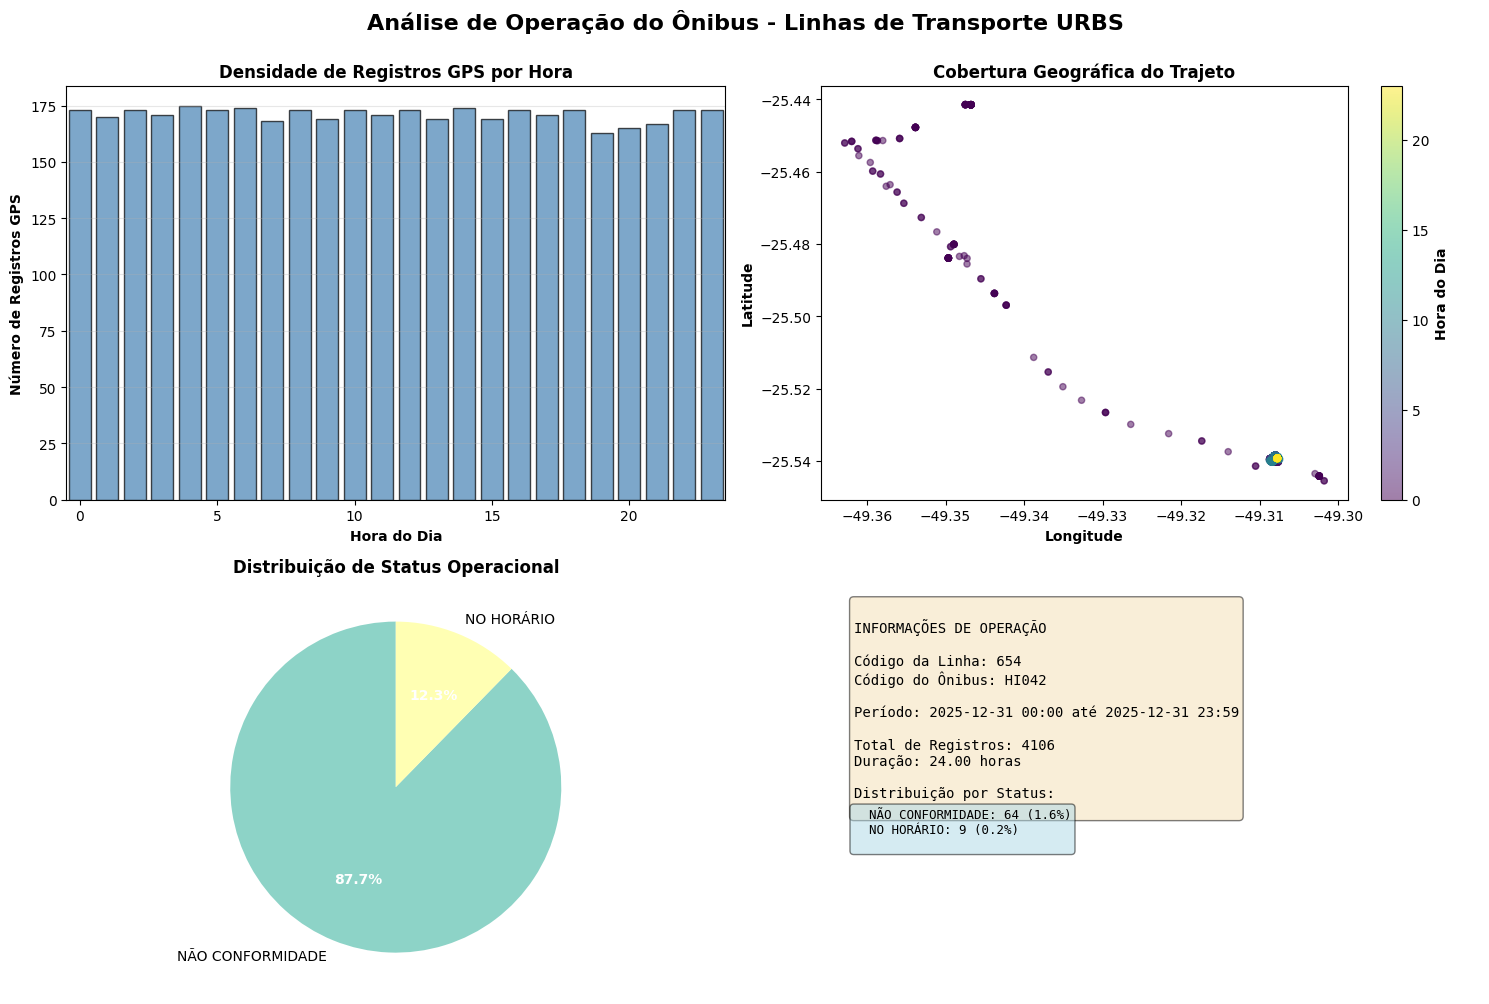


✓ Gráficos de análise das linhas de ônibus gerados com sucesso!


In [12]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import seaborn as sns

print("\n" + "=" * 60)
print("SEÇÃO 5: GRÁFICOS COM AS LINHAS DE ÔNIBUS")
print("=" * 60)

if not df_resultado.empty:
    # Preparar dados para visualização
    print("\n1. Preparando dados para visualizações...")
    
    # Se houver dados de linha (CODIGOLINHA)
    if 'CODIGOLINHA' in df_resultado.columns:
        linhas_unicas = df_resultado['CODIGOLINHA'].nunique()
        print(f"   ✓ Linhas de ônibus encontradas: {linhas_unicas}")
    
    # Contar registros por hora
    df_resultado['hora'] = pd.to_datetime(df_resultado['request_timestamp']).dt.hour
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('Análise de Operação do Ônibus - Linhas de Transporte URBS', 
                 fontsize=16, fontweight='bold', y=1.00)
    
    # Gráfico 1: Distribuição de registros por hora do dia
    print("\n2. Plotando gráfico 1: Registros por hora...")
    registros_por_hora = df_resultado['hora'].value_counts().sort_index()
    axes[0, 0].bar(registros_por_hora.index, registros_por_hora.values, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0, 0].set_xlabel('Hora do Dia', fontweight='bold')
    axes[0, 0].set_ylabel('Número de Registros GPS', fontweight='bold')
    axes[0, 0].set_title('Densidade de Registros GPS por Hora', fontweight='bold')
    axes[0, 0].grid(axis='y', alpha=0.3)
    axes[0, 0].set_xlim(-0.5, 23.5)
    
    # Gráfico 2: Distribuição da cobertura geográfica (LAT/LON)
    print("3. Plotando gráfico 2: Distribuição geográfica...")
    axes[0, 1].scatter(df_resultado['LON'], df_resultado['LAT'], 
                       alpha=0.5, c=df_resultado['hora'], cmap='viridis', s=20)
    axes[0, 1].set_xlabel('Longitude', fontweight='bold')
    axes[0, 1].set_ylabel('Latitude', fontweight='bold')
    axes[0, 1].set_title('Cobertura Geográfica do Trajeto', fontweight='bold')
    cbar = plt.colorbar(axes[0, 1].collections[0], ax=axes[0, 1])
    cbar.set_label('Hora do Dia', fontweight='bold')
    
    # Gráfico 3: Status operacional (SITUACAO)
    print("4. Plotando gráfico 3: Status operacional...")
    if 'SITUACAO' in df_resultado.columns:
        status_count = df_resultado['SITUACAO'].value_counts()
        cores = plt.cm.Set3(range(len(status_count)))
        wedges, texts, autotexts = axes[1, 0].pie(
            status_count.values, 
            labels=status_count.index,
            autopct='%1.1f%%',
            colors=cores,
            startangle=90
        )
        axes[1, 0].set_title('Distribuição de Status Operacional', fontweight='bold')
        for autotext in autotexts:
            autotext.set_color('white')
            autotext.set_fontweight('bold')
    
    # Gráfico 4: Linha de ônibus operada
    print("5. Plotando gráfico 4: Linhas operadas...")
    if 'CODIGOLINHA' in df_resultado.columns and 'COD' in df_resultado.columns:
        linha_info = f"Código da Linha: {df_resultado['CODIGOLINHA'].iloc[0]}"
        onibus_info = f"Código do Ônibus: {df_resultado['COD'].iloc[0]}"
        periodo_info = f"Período: {df_resultado['request_timestamp'].min().strftime('%Y-%m-%d %H:%M')} até {df_resultado['request_timestamp'].max().strftime('%Y-%m-%d %H:%M')}"
        registros_info = f"Total de Registros: {len(df_resultado)}"
        duracao_info = f"Duração: {(df_resultado['request_timestamp'].max() - df_resultado['request_timestamp'].min()).total_seconds() / 3600:.2f} horas"
        
        # Criar uma tabela de informações
        axes[1, 1].axis('off')
        
        info_text = f"""
INFORMAÇÕES DE OPERAÇÃO

{linha_info}
{onibus_info}

{periodo_info}

{registros_info}
{duracao_info}

Distribuição por Status:
"""
        
        axes[1, 1].text(0.05, 0.95, info_text, 
                       transform=axes[1, 1].transAxes,
                       fontsize=10, verticalalignment='top',
                       fontfamily='monospace',
                       bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        # Adicionar status breakdown
        if 'SITUACAO' in df_resultado.columns:
            status_breakdown = df_resultado['SITUACAO'].value_counts()
            status_text = ""
            for status, count in status_breakdown.items():
                pct = (count / len(df_resultado)) * 100
                status_text += f"  {status}: {count} ({pct:.1f}%)\n"
            
            axes[1, 1].text(0.05, 0.45, status_text,
                          transform=axes[1, 1].transAxes,
                          fontsize=9, verticalalignment='top',
                          fontfamily='monospace',
                          bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    
    plt.tight_layout()
    plt.show()
    
    print("\n✓ Gráficos de análise das linhas de ônibus gerados com sucesso!")
    
else:
    print("❌ Sem dados para gerar gráficos")

## Resumo e Próximas Etapas

Este notebook implementou com sucesso as 5 primeiras etapas da metodologia do TCC:

### ✓ Etapas Concluídas:

1. **Carregamento de Dados**: Ingestão de arquivos CSV da URBS com preservação de colunas enriquecidas (status operacional)
2. **Limpeza e Validação**: Remoção de registros inválidos, conversão de tipos, remoção de duplicatas
3. **Interpolação Temporal**: Criação de trajetória contínua minuto a minuto usando interpolação linear
4. **Visualização Interativa**: Mapa Folium com trajeto, pontos GPS e marcadores de início/fim
5. **Gráficos de Análise**: Visualizações das linhas operadas, distribuição temporal e status operacional

### 📊 Próximas Etapas (não implementadas neste notebook):

Para completar a aplicação completa de Process Mining conforme o TCC:

- **Geofencing e Map Matching**: Cruzamento com pontos de parada da URBS para identificar eventos de chegada/partida
- **Construção do Event Log**: Formatação em padrão XES/CSV para PM4Py
- **Descoberta de Processos**: Aplicação do algoritmo Inductive Miner
- **Conformance Checking**: Verificação contra rotas planejadas
- **Análise de Desempenho**: Identificação de gargalos e desvios operacionais

### 📝 Notas Técnicas:

- Os dados são armazenados em `/home/arosisca/GIT/TCC_2026/dados_urbs/`
- Pontos de parada estão em `/home/arosisca/GIT/TCC_2026/dados_ponto_onibus/pontos_de_onibus.json`
- A biblioteca PM4Py pode ser integrada para as análises de processo mining
- GeoDataFrame é utilizado para operações espaciais com precisão em UTM (EPSG:31982)